# VaR y CVaR de portafolios correlacionados

Se calcula el **Valor en Riesgo (VaR)** y el **VaR Condicional (CVaR)** al 5% de tres portafolios con AAPL, MSFT y NVDA, simulados con correlación mediante Cholesky.

| Portafolio | Pesos $w$ (AAPL, MSFT, NVDA) |
|---|---|
| P1 | [1, 0, 0] |
| P2 | [0.33, 0.33, 0.34] |
| P3 | [0.2, 0.2, 0.6] |

**Inversión inicial:** $V_0 = 100{,}000$ USD

**Contenido:**
1. Simulación de precios correlacionados (mismo método de la actividad anterior).
2. Valor final y pérdidas y ganancias de cada portafolio.
3. VaR y CVaR al 5%.
4. Histogramas con cuartiles, VaR y CVaR.

---

### Librerías

In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

---

# Parte 1. Simulación de precios correlacionados

$$S_i(T) = S_i(0)\, e^{\left(r_i - \frac{1}{2}\Sigma_{ii}\right)T + \sqrt{T}\, Z_i}, \qquad Z = L\,\varepsilon$$

- $r_i$: rendimiento anual de la acción, estimado con el último año de datos.
- $\Sigma_{ii}$: varianza anual de la acción (diagonal de la matriz de covarianzas).
- $L$: factor de Cholesky de $\Sigma$.

### Descarga de AAPL, MSFT y NVDA (últimos 3 años)

In [3]:
tickers_tec = ["AAPL", "MSFT", "NVDA"]

data_tec = yf.download(tickers_tec, start="2023-11-01", end="2026-11-01",
                       auto_adjust=True, progress=False)

precios_tec = data_tec["Close"][tickers_tec].dropna()
print(f"Observaciones: {len(precios_tec)}")
precios_tec.tail()

Observaciones: 752


Ticker,AAPL,MSFT,NVDA
Date,,,
2026-10-26,343.910004,532.599976,216.000000
2026-10-27,347.100006,531.330017,217.940002
2026-10-28,343.829987,531.010010,215.380005
2026-10-29,348.910004,530.140015,213.660004
2026-10-30,344.630005,521.909973,204.639999


### Rendimientos logarítmicos y covarianza anualizada

In [4]:
log_ret_tec = np.log(precios_tec / precios_tec.shift(1)).dropna()
covarianza  = log_ret_tec.cov() * 252

covarianza.round(4)

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,0.0712,0.0231,0.0353
MSFT,0.0231,0.0672,0.0509
NVDA,0.0353,0.0509,0.2168


### Rendimiento esperado de cada acción (último año)

$$r_i = 252 \cdot \overline{\ln\left(\frac{S_t}{S_{t-1}}\right)}$$

In [5]:
r_tec = log_ret_tec.iloc[-252:].mean() * 252

pd.DataFrame({"r (log anual)": r_tec,
              "Rend. simple (%)": (np.exp(r_tec) - 1) * 100}).round(4)

,r (log anual),Rend. simple (%)
Ticker,,
AAPL,0.2488,28.2548
MSFT,-0.0287,-2.8337
NVDA,-0.0093,-0.9224


### Cholesky y choques correlacionados Z = L ε

In [6]:
M = 10_000
T = 1
Sigma = covarianza.values
L = np.linalg.cholesky(Sigma)

np.random.seed(42)
epsilon = np.random.normal(0, 1, [M, len(tickers_tec)])

Z_tec = epsilon @ L.T

### Precios a un año

In [7]:
S0_tec = precios_tec.iloc[-1]
drift  = (r_tec.values - 0.5 * np.diag(Sigma)) * T

ST_tec = S0_tec.values * np.exp(drift + np.sqrt(T) * Z_tec)
ST_tec = pd.DataFrame(ST_tec, columns=tickers_tec)

pd.DataFrame({"S0": S0_tec,
              "Media S_T simulada": ST_tec.mean(),
              "E[S_T] teórico": S0_tec.values * np.exp(r_tec.values * T)}).round(2)

,S0,Media S_T simulada,E[S_T] teórico
AAPL,344.63,441.44,442.00
MSFT,521.91,507.10,507.12
NVDA,204.64,202.40,202.75


---

# Parte 2. Valor final y pérdidas y ganancias

$$V_T = V_0 \sum_i w_i \frac{S_i(T)}{S_i(0)} \qquad \text{P\&L} = V_T - V_0$$

In [8]:
V0 = 100_000

portafolios_tec = {
    "P1": np.array([1, 0, 0]),
    "P2": np.array([0.33, 0.33, 0.34]),
    "P3": np.array([0.2, 0.2, 0.6]),
}

rend_bruto = ST_tec.values / S0_tec.values

VT_tec = pd.DataFrame({nombre: V0 * rend_bruto @ w
                       for nombre, w in portafolios_tec.items()})
PnL = VT_tec - V0

pd.DataFrame({"V_T promedio": VT_tec.mean(),
              "P&L promedio": PnL.mean()}).round(2)

,V_T promedio,P&L promedio
P1,128091.32,28091.32
P2,107961.20,7961.20
P3,104393.50,4393.50


---

# Parte 3. VaR y CVaR

**VaR al 5%:** la pérdida que solo se supera en el 5% de los peores escenarios. Se obtiene del percentil 5% del P&L:

$$\text{VaR}_{5\%} = -\,P_{5\%}(\text{P\&L})$$

Se lee así: "con 95% de confianza, en un año no se pierde más que el VaR".

**CVaR al 5%** (o *Expected Shortfall*): la pérdida **promedio** dentro de ese 5% de peores escenarios:

$$\text{CVaR}_{5\%} = -\,E\left[\text{P\&L} \;\middle|\; \text{P\&L} \le P_{5\%}\right]$$

El VaR dice dónde empieza la cola de pérdidas, pero no qué tan profunda es. El CVaR responde justo eso: si caemos en el 5% malo, cuánto se pierde en promedio. Por eso el CVaR siempre es mayor o igual que el VaR.

**Cuartiles:** $Q_1$, $Q_2$ (mediana) y $Q_3$ dividen los escenarios en cuatro partes iguales. Entre $Q_1$ y $Q_3$ está el 50% central de los resultados.

### Tabla de cuartiles, VaR y CVaR

In [9]:
alpha = 0.05

riesgo = {}
for p in PnL.columns:
    datos = PnL[p]
    p5    = datos.quantile(alpha)
    cola  = datos[datos <= p5]

    riesgo[p] = {
        "Q1": datos.quantile(0.25),
        "Q2 (mediana)": datos.quantile(0.50),
        "Q3": datos.quantile(0.75),
        "Percentil 5%": p5,
        "VaR 5%": -p5,
        "CVaR 5%": -cola.mean(),
        "Escenarios en la cola": len(cola),
    }

riesgo = pd.DataFrame(riesgo).T
riesgo.round(2)

,Q1,Q2 (mediana),Q3,Percentil 5%,VaR 5%,CVaR 5%,Escenarios en la cola
P1,2968.02,23592.61,48170.48,-20258.92,20258.92,28625.00,500.0
P2,-11741.10,4359.07,23226.63,-29159.32,29159.32,35489.19,500.0
P3,-19528.33,-1690.37,22202.23,-38606.37,38606.37,44807.82,500.0


### VaR y CVaR como porcentaje de la inversión

In [10]:
pd.DataFrame({
    "VaR 5% (%)":  riesgo["VaR 5%"]  / V0 * 100,
    "CVaR 5% (%)": riesgo["CVaR 5%"] / V0 * 100,
    "CVaR / VaR":  riesgo["CVaR 5%"] / riesgo["VaR 5%"],
}).round(2)

,VaR 5% (%),CVaR 5% (%),CVaR / VaR
P1,20.26,28.63,1.41
P2,29.16,35.49,1.22
P3,38.61,44.81,1.16


---

# Parte 4. Histogramas con cuartiles, VaR y CVaR

Las barras rojas son el 5% de peores escenarios, es decir, la cola que mide el VaR. Las líneas negras marcan los cuartiles, la naranja el VaR y la morada el CVaR (el promedio de la zona roja).

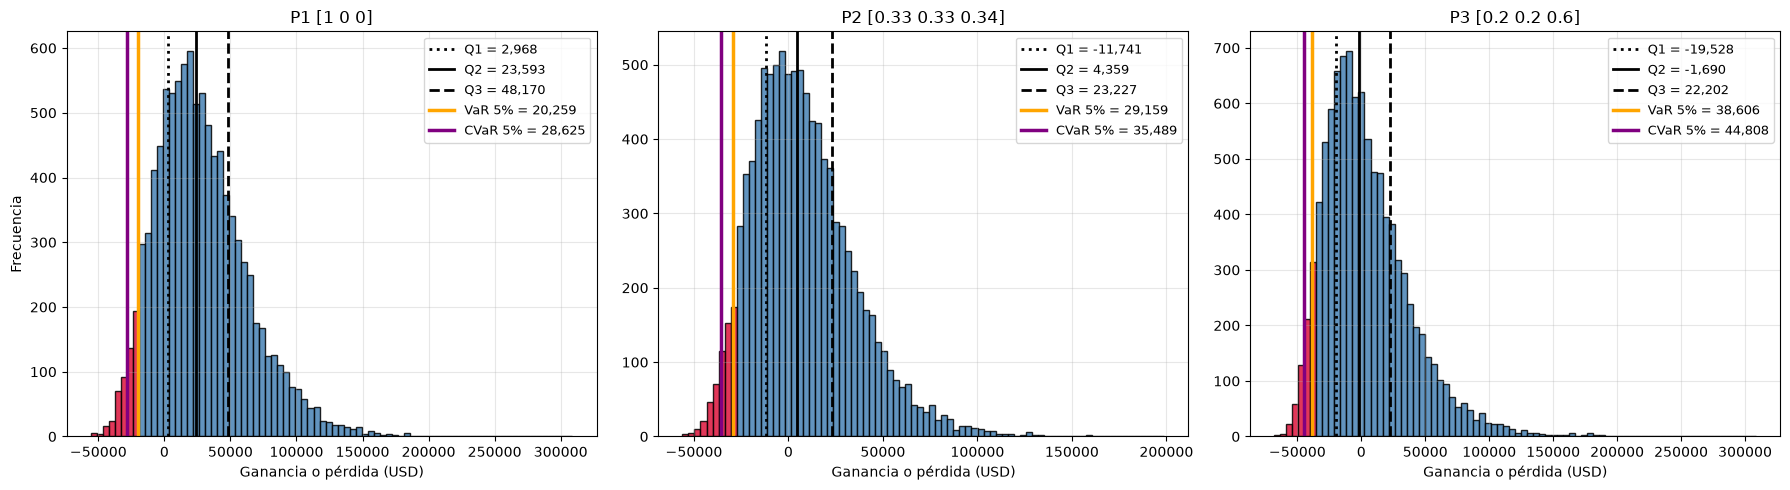

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, p in zip(axes, PnL.columns):
    datos = PnL[p]
    q1, q2, q3 = datos.quantile([0.25, 0.50, 0.75])
    p5   = datos.quantile(alpha)
    cvar = datos[datos <= p5].mean()

    n_barras, bins, barras = ax.hist(datos, bins=80, color="steelblue",
                                     edgecolor="black", alpha=0.85)
    for barra, borde_izq in zip(barras, bins[:-1]):
        if borde_izq < p5:
            barra.set_facecolor("crimson")

    ax.axvline(q1, color="black", ls=":",  lw=2, label=f"Q1 = {q1:,.0f}")
    ax.axvline(q2, color="black", ls="-",  lw=2, label=f"Q2 = {q2:,.0f}")
    ax.axvline(q3, color="black", ls="--", lw=2, label=f"Q3 = {q3:,.0f}")
    ax.axvline(p5,   color="orange", lw=2.5, label=f"VaR 5% = {-p5:,.0f}")
    ax.axvline(cvar, color="purple", lw=2.5, label=f"CVaR 5% = {-cvar:,.0f}")

    ax.set_title(f"{p} {portafolios_tec[p]}")
    ax.set_xlabel("Ganancia o pérdida (USD)")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

axes[0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

### Comparación del VaR y CVaR de los tres portafolios

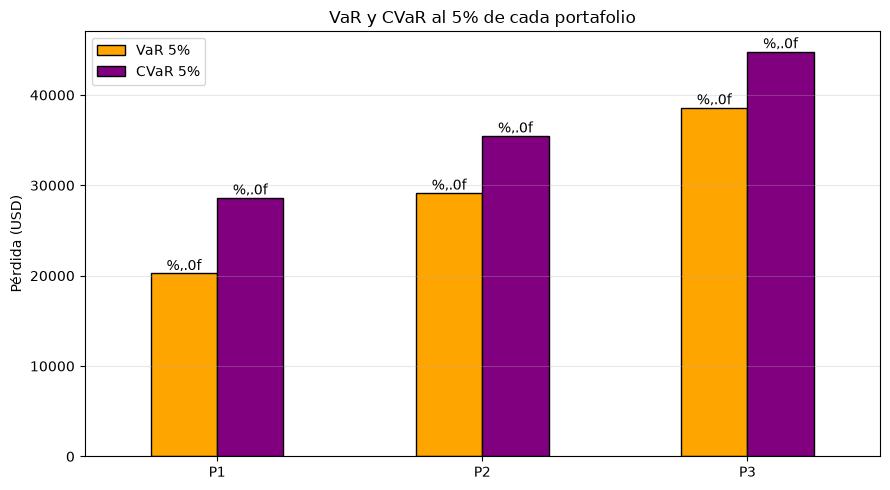

In [12]:
ax = riesgo[["VaR 5%", "CVaR 5%"]].plot(kind="bar", figsize=(9, 5), rot=0,
                                         color=["orange", "purple"], edgecolor="black")
for barras in ax.containers:
    ax.bar_label(barras, fmt="%,.0f", fontsize=10)

ax.set_ylabel("Pérdida (USD)")
ax.set_title("VaR y CVaR al 5% de cada portafolio")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()